# Distributional Incidence — Who Pays Federal Taxes, Who Gets Transfers, and Who Would Get a Child Transfer

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** CBO *The Distribution of Household Income, 2023* and Census CPS ASEC 2024 (income year 2023)

This notebook uses **real data only**. There is no synthetic generator and no fallback. The tax and transfer incidence is read from a
workbook CBO published; the incidence of a stylised transfer is computed from CPS ASEC weighted cells (no person-level row is read,
printed or stored). The two sources define income differently, and the notebook reconciles them in the open instead of rescaling either.

The analysis was fixed in a written plan (`pap/E03_plan.md`) committed before any retrieval, and two amendments. Amendment 1 was committed before the first CPS retrieval. Amendment 2 was committed
after the first CPS retrieval had stopped on amendment 1's withheld-weight rule, on the owner's ruling, and before any incidence was computed; the withheld-weight bound it sets was therefore chosen after that figure was seen.
Every provenance record carries the plan and the amendments in force when it was written, and a run ledger beside the records lists every retrieval, including the one that stopped. The notebook says where it departs from the plan.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Read** a distributional table (average income, transfers and taxes by income quintile) and turn averages into shares of a total.
2. **Rank** people by household income adjusted for household size, and place a boundary inside a bin when income is known only to its bin.
3. **Compute** the incidence of a stylised transfer by income quintile, race and ethnicity, and the age of the household's reference person.
4. **Report** a survey share with the interval a simple random sample would give, and say why that interval is only an approximation, and compare it with the survey's own replicate-weight interval.
5. **Bound** a share by the weight a small-cell rule withheld, and say when a difference survives that bound.
6. **Reconcile** two income concepts side by side without pretending they agree.

## Prerequisites

**Knowledge.** Weighted shares; quantiles of a weighted distribution; the difference between an average and a total.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you as the environment variable
`CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path you set in `KRL_SECRETS_PATH`. The key is read at runtime and is
never printed or written into this notebook's output. The CPS retrieval is one API request; the first run also downloads the Census Bureau's replicate-weight files (about 73 megabytes in all) into a cache outside the repository (`~/.cache/telosyn-notebooks`, or `$TELOSYN_CACHE_DIR`), each checked against a pinned size and SHA-256, and takes a few minutes. The CBO workbook is
committed in the repository (`data/cbo/`) and needs no key.

**Packages.** `pandas`, `numpy`, `matplotlib`, `openpyxl`, and the local `krl_tutorials_data` package (`methods.incidence`).

**Prior notebooks.** E01 for how a cost is built from a government file; none is required.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| `62761-supp-data.xlsx`, sheets 1, 2, 3, 10, 11 and 12 | Congressional Budget Office, *The Distribution of Household Income, 2023* (publication 62761), committed under `data/cbo/` with its digest and the way it was obtained in `SOURCES.md` | average income, means-tested transfers and federal taxes by quintile; people and children by quintile; quintile boundaries |
| `HTOTVAL`, `H_NUMPER`, `A_AGE`, `PRDTRACE`, `PEHSPNON`, `A_EXPRRP`, `MARSUPWT` | Census Bureau, Current Population Survey Annual Social and Economic Supplement 2024 (income year 2023), through the API, as weighted cells only | the stylised transfer's incidence |
| `CPS_ASEC_ASCII_REPWGT_2024.ZIP`, its `.SAS` layout and `2024_ASEC_Replicate_Weight_Usage_Instructions.docx` | Census Bureau, the three approved downloads (see `data/cps/SOURCES.md`), cached outside the repository and never committed | the 160 replicate weights, merged to the API records on the SAS layout's keys, for replicate-weight standard errors |

Each retrieval is recorded in `provenance/`, bound to the plan's SHA-256.

> **Two income concepts, and what each includes.** Both rank people by household income divided by the square root of the number of people in the household. They are not the same income.

| | CBO: income before transfers and taxes (the ranking income) | CPS: household money income (`HTOTVAL`) |
|---|---|---|
| Wages and salaries | included, with employers' contributions to health insurance and the payroll taxes employers pay | included as reported; no employer contributions |
| Business, capital and other market income | included, with realised capital gains | included as reported by respondents; the Census definition of money income leaves out realised capital gains |
| Social insurance benefits | Social Security, Medicare (at cost to the government), unemployment insurance, workers' compensation | Social Security, unemployment and workers' compensation as reported; Medicare is not valued |
| Means-tested transfers | **excluded** from the ranking income (reported separately) | cash assistance and Supplemental Security Income are **included**; in-kind benefits (Medicaid, SNAP) are not valued |
| Taxes | before federal taxes | before taxes |
| Negative incomes | households with negative income are left out of the lowest group, kept in the totals | kept, in a bin below zero |
| Source of the figures | tax records and survey data combined, with modelled allocations of some taxes | survey responses, with the under-reporting and topcoding that implies |

Sources: the notes on the first sheet of the CBO workbook for the left column; the Census Bureau's definition of money income for the right (older Census publications; not re-checked against the 2024 variable documentation in this build).
The reconciliation section lines the two up without deciding how much of the gap each difference explains.

## Design

**Estimands, all descriptive, all for income year 2023.**

1. *CBO incidence.* For each income quintile: average market income, social insurance benefits, means-tested transfers, federal taxes and income
   after transfers and taxes, and each quintile's share of the totals, as CBO published them. These are CBO's modelled allocations (for example, the corporate income tax is split between capital and labour, employers' payroll taxes are charged to workers, and Medicaid is valued at
   cost to the government), not a count of who writes the cheque and not an estimate of what a change would do.
2. *Where the children are, as the cost shares of a stylised transfer.* A fixed amount per child, paid to the child's household, with full take-up. Because the amount is the same for every child, a group's share of the cost is its share of children: the shares are estimates of where children are,
   by quintile of people ranked by household income adjusted for size, by race and ethnicity, and by the age of the household's reference person. This is first-round statutory cash incidence, not a simulation of a policy: there is no take-up, phase-out, taxation or behavioural response.
   The amount and the age limit are set in the configuration cell.
3. *Reconciliation.* How far the CPS ranking sits from CBO's.

**Rules fixed before the data.** A CPS difference is called "suggested by the sample" only when the sampling interval (a simple-random-sample approximation; the replicate-weight interval below is the better guide) excludes zero *and* the
difference keeps its sign across the bound set by the weight the small-cell rule withheld; otherwise it is "not distinguishable from zero at the precision of this data".

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data import provenance
from krl_tutorials_data.connectors import BulkFileSource, frame_from_bulk_file
from krl_tutorials_data.methods import incidence
from krl_tutorials_data.sources import fetch_cps_asec

NB_DIR = REPO_ROOT / "projects" / "10-economic-evaluation" / "E03_distributional_incidence"
PLAN = NB_DIR / "pap" / "E03_plan.md"
AMEND = [NB_DIR / "pap" / "E03_plan_amendment_1.md", NB_DIR / "pap" / "E03_plan_amendment_2.md"]
PLAN_SHA256 = hashlib.sha256(PLAN.read_bytes()).hexdigest()
provenance.use_ledger(NB_DIR / "provenance" / "_runs.jsonl", PLAN, *AMEND)   # every fetch below appends to the run ledger, before it raises as well as after it succeeds


def stop(message: str) -> None:
    """Append a stopped line to the run ledger, then raise."""
    provenance.ledger_stop(message)
    raise SystemExit(message)

CBO_FILE = REPO_ROOT / "data" / "cbo" / "62761-supp-data.xlsx"
CBO_SHA256 = "e91c2e8e5012628d8e884e5ad4fc86f2f004cad9113708bbc1038d7ab7b4acbd"

CPS_YEAR = 2024                 # income year 2023
YEAR = 2023
BIN_WIDTH, INCOME_FLOOR, INCOME_CAP = 2500.0, 0.0, 150_000.0   # amendment 1
MIN_CELL_RECORDS = 10                                           # amendment 1
FIRST_BOUND = 0.01              # amendment 1
WITHHELD_BOUND = 0.02           # amendment 2, set after the first retrieval had exceeded FIRST_BOUND, on the owner's ruling
BOUNDARY_BIN_MAX = 0.05         # amendment 1
CHILD_AGE, TRANSFER_PER_CHILD = 18, 1000.0
QUINTILES = ["Lowest quintile", "Second quintile", "Middle quintile", "Fourth quintile", "Highest quintile"]
ADDED = "not pre-specified (added after review, 2026-10-28)"
ADDED29 = "not pre-specified (added after review, 2026-10-29)"

PLAN_HISTORY = [  # file, author time (UTC) of the commit that first held it, relation to the first CPS retrieval; the same times are in krl.pap, which the plan-binding gate checks against git history
    ("E03_plan.md", "19:23:37Z", "before"),
    ("E03_plan_amendment_1.md", "19:42:38Z", "before"),
    ("E03_plan_amendment_2.md", "20:27:00Z", "after"),
]
FIRST_RETRIEVAL_UTC = "20:04:05Z"
print(f"plan and amendments (first CPS retrieval, the one that stopped on amendment 1's rule, at {FIRST_RETRIEVAL_UTC} on 2026-10-27)")
for (name_, when_, rel_), path_ in zip(PLAN_HISTORY, [PLAN, *AMEND]):
    print(f"  {name_:26s} author time {when_}  {rel_} that retrieval  SHA-256 {hashlib.sha256(path_.read_bytes()).hexdigest()[:12]}")
print("the amendments cite their predecessors by commit id as they stood when written (the plan as f44a811, amendment 1 as dbf5ce3); ids change when a branch is rebased, so those two ids are the plan and amendment 1 above, identified by SHA-256")
print(f"plan SHA-256         : {PLAN_SHA256}")
print(f"CBO workbook SHA-256 : {CBO_SHA256}")
print(f"bins                 : ${BIN_WIDTH:,.0f} wide, one bin at or above ${INCOME_CAP:,.0f}, one below ${INCOME_FLOOR:,.0f}; cells under {MIN_CELL_RECORDS} records are withheld")
print(f"stop rules           : withheld weight above {FIRST_BOUND:.0%} of the population (amendment 1), moved to {WITHHELD_BOUND:.0%} by amendment 2; a boundary bin holding {BOUNDARY_BIN_MAX:.0%} or more")
print(f"stylised transfer    : ${TRANSFER_PER_CHILD:,.0f} per person under {CHILD_AGE}, paid to the household")

plan and amendments (first CPS retrieval, the one that stopped on amendment 1's rule, at 20:04:05Z on 2026-10-27)
  E03_plan.md                author time 19:23:37Z  before that retrieval  SHA-256 74d2a906ac0b
  E03_plan_amendment_1.md    author time 19:42:38Z  before that retrieval  SHA-256 0a22788b520d
  E03_plan_amendment_2.md    author time 20:27:00Z  after that retrieval  SHA-256 c0847b6d350e
the amendments cite their predecessors by commit id as they stood when written (the plan as f44a811, amendment 1 as dbf5ce3); ids change when a branch is rebased, so those two ids are the plan and amendment 1 above, identified by SHA-256
plan SHA-256         : 74d2a906ac0b5107064cc2f0aa17ed43a67701738d166997d7f6144b33fff15a
CBO workbook SHA-256 : e91c2e8e5012628d8e884e5ad4fc86f2f004cad9113708bbc1038d7ab7b4acbd
bins                 : $2,500 wide, one bin at or above $150,000, one below $0; cells under 10 records are withheld
stop rules           : withheld weight above 1% of the population (am

## Part 1 · What CBO publishes

The workbook is committed and read through `connectors`, which fails closed if its bytes differ from the recorded digest. Each table's title and
header row are located by their text, not by position, so a change in layout stops the notebook instead of misaligning it.

In [2]:
"""Read the CBO workbook's tables for 2023; the file is pinned by its digest."""
source = BulkFileSource(
    path=CBO_FILE, publisher="Congressional Budget Office",
    dataset="The Distribution of Household Income, 2023 - supplemental data",
    vintage="September 2026 report (publication 62761)", retrieved_on=date(2026, 10, 27),
    sha256=CBO_SHA256, terms_url="https://www.cbo.gov/about/website-policies",
    notes=("Downloaded by the owner in a browser; the publisher's bot protection refuses scripted clients. See data/cbo/SOURCES.md.",),
)
SHEETS = {"demographics": "1. Demographics", "minimums": "2. Income Group Mins", "average": "3. Avg HH Income",
          "share_income": "10. Household Income Shares", "share_transfers": "11. Means-Tested Trans Shares",
          "share_taxes": "12. Federal Taxes Shares"}


def read_table(path: Path, sheet: str) -> pd.DataFrame:
    """One CBO table as a frame: header row found by its first cell, all years kept."""
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    first = raw[0].astype(str)
    hdr = first[first.isin(["Income group", "Household size"])].index
    if len(hdr) != 1:
        stop(f"{sheet}: expected one header row, found {len(hdr)}")
    names = [str(v).replace("\n", " ").strip() for v in raw.iloc[hdr[0]]]
    table = raw.iloc[hdr[0] + 1:].copy()
    table.columns = names
    table = table[pd.to_numeric(table["Year"], errors="coerce").notna()].copy()
    table["Year"] = table["Year"].astype(int)
    return table.reset_index(drop=True)


cbo = {}
for key, sheet in SHEETS.items():
    frame, prov = frame_from_bulk_file(source, lambda p, s=sheet: read_table(p, s))
    prov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / f"e03_cbo_{key}.json")
    cbo[key] = frame[frame["Year"] == YEAR].reset_index(drop=True)
    print(f"{sheet:32s}: {len(frame):4d} rows, {len(cbo[key])} for {YEAR}; digest {prov.content_sha256[:12]}")

1. Demographics                 :  450 rows, 10 for 2023; digest e91c2e8e5012
2. Income Group Mins            :  180 rows, 4 for 2023; digest e91c2e8e5012
3. Avg HH Income                :  450 rows, 10 for 2023; digest e91c2e8e5012
10. Household Income Shares     :  450 rows, 10 for 2023; digest e91c2e8e5012
11. Means-Tested Trans Shares   :  450 rows, 10 for 2023; digest e91c2e8e5012


12. Federal Taxes Shares        :  450 rows, 10 for 2023; digest e91c2e8e5012


### Average income, transfers and taxes by quintile

CBO's averages are *per household*. Quintiles hold different numbers of households (and of people), so a quintile's share of a total is its
average times its households, divided by the same product summed over quintiles. The notebook recomputes the shares that way and checks them against
the shares CBO printed.

*The plan said to divide each quintile's value by the sum across quintiles. That is not a share of the total when the quintiles hold different numbers of households, so the notebook uses CBO's own published shares and checks them against average times households: not pre-specified (added after review, 2026-10-29).*

In [3]:
avg = cbo["average"].set_index("Income group")
dem = cbo["demographics"].set_index("Income group")
cols = ["Market income", "Social insurance benefits", "Income before transfers and taxes", "Means-tested transfers", "Federal taxes", "Income after transfers and taxes"]
show = avg.loc[QUINTILES + ["All quintiles"], cols].astype(float)
show.insert(0, "Households (millions)", dem.loc[QUINTILES + ["All quintiles"], "Number of households"].astype(float))
show.insert(1, "People (millions)", dem.loc[QUINTILES + ["All quintiles"], "Number of people"].astype(float))
print(f"CBO {YEAR}: average per household, 2023 dollars")
print(show.to_string(float_format=lambda v: f"{v:,.0f}" if abs(v) >= 1000 else f"{v:,.1f}"))
for c in ("Means-tested transfers", "Federal taxes"):
    low, high = show.loc["Lowest quintile", c], show.loc["Highest quintile", c]
    print(f"{c}: lowest quintile ${low:,.0f}, highest quintile ${high:,.0f} per household")
direction_transfers = float(show.loc["Lowest quintile", "Means-tested transfers"]) > float(show.loc["Highest quintile", "Means-tested transfers"])
direction_taxes = float(show.loc["Highest quintile", "Federal taxes"]) > float(show.loc["Lowest quintile", "Federal taxes"])
print(f"FALSIFICATION: direction_cbo statistic={int(direction_transfers and direction_taxes)} transfers fall and taxes rise from lowest to highest quintile verdict={'PASS' if direction_transfers and direction_taxes else 'FAIL'}")

CBO 2023: average per household, 2023 dollars
                  Households (millions)  People (millions)  Market income  Social insurance benefits  Income before transfers and taxes  Means-tested transfers  Federal taxes  Income after transfers and taxes
Income group                                                                                                                                                                                                    
Lowest quintile                    26.1               63.8         20,900                      7,600                             28,500                  20,100          100.0                            48,400
Second quintile                    27.1               64.9         47,200                     15,900                             63,100                   9,900          6,000                            67,000
Middle quintile                    27.0               64.9         79,300                     19,300                  

In [4]:
"""Shares of totals: recomputed (average x households) against the shares CBO printed."""
print(ADDED29 + ": the plan said to divide each quintile's average by the sum of the five averages; that is not a share of the total (the quintiles hold different numbers of households), so CBO's published shares are used and checked against average times households (decided on seeing the file, 2026-10-27)")
hh = dem.loc[QUINTILES, "Number of households"].astype(float)
pairs = {"Income before transfers and taxes": ("share_income", "Income before transfers and taxes"),
         "Means-tested transfers": ("share_transfers", "Means-tested transfers"),
         "Federal taxes": ("share_taxes", "Federal taxes")}
rows, worst = [], 0.0
for name, (key, col) in pairs.items():
    published = cbo[key].set_index("Income group").loc[QUINTILES, col].astype(float)
    total = (avg.loc[QUINTILES, name].astype(float) * hh)
    recomputed = 100 * total / total.sum()
    worst = max(worst, float((recomputed - published).abs().max()))
    for q in QUINTILES:
        rows.append({"measure": name, "quintile": q, "published %": published[q], "recomputed %": recomputed[q]})
    print(f"{name}: lowest quintile {published['Lowest quintile']:.1f}% (published) {recomputed['Lowest quintile']:.1f}% (recomputed); highest {published['Highest quintile']:.1f}% and {recomputed['Highest quintile']:.1f}%")
cbo_shares = pd.DataFrame(rows)
print(f"largest gap between published and recomputed shares: {worst:.2f} percentage points")
print(f"FALSIFICATION: cbo_shares_recomputed statistic={worst:.3f} percentage points; CBO rounds dollars to the nearest hundred and shares to a tenth, so a gap above 0.5 is a failure verdict={'PASS' if worst <= 0.5 else 'FAIL'}")
note_sum = float(cbo['share_transfers'].set_index('Income group').loc[QUINTILES, 'Means-tested transfers'].astype(float).sum())
print(f"published shares of means-tested transfers add to {note_sum:.1f}%; negative-income households sit outside the lowest quintile but inside the totals, so the sum can fall short of 100")

not pre-specified (added after review, 2026-10-29): the plan said to divide each quintile's average by the sum of the five averages; that is not a share of the total (the quintiles hold different numbers of households), so CBO's published shares are used and checked against average times households (decided on seeing the file, 2026-10-27)
Income before transfers and taxes: lowest quintile 3.8% (published) 3.8% (recomputed); highest 54.7% and 54.3%
Means-tested transfers: lowest quintile 48.9% (published) 49.2% (recomputed); highest 4.2% and 4.2%
Federal taxes: lowest quintile 0.1% (published) 0.1% (recomputed); highest 69.8% and 69.9%
largest gap between published and recomputed shares: 0.42 percentage points
FALSIFICATION: cbo_shares_recomputed statistic=0.425 percentage points; CBO rounds dollars to the nearest hundred and shares to a tenth, so a gap above 0.5 is a failure verdict=PASS
published shares of means-tested transfers add to 99.2%; negative-income households sit outside the

## Part 2 · A stylised transfer in the CPS

The CPS ASEC is retrieved as weighted cells of (household income adjusted for size, in bins) × race and ethnicity × the age group of the household's
reference person × a child indicator. A cell under the floor is withheld and counted (decided on the main weight). The API serves no replicate weights; the client also reads the Bureau's replicate-weight file and returns, for each cell, the sum of each of the 160 replicate weights (aggregates only, never person rows). The pre-specified sampling intervals use Kish's effective sample size; a labelled analysis below adds replicate-weight intervals beside them.

In [5]:
"""One CPS ASEC request, cells only, bound to the plan."""
cells, cps_prov = fetch_cps_asec(year=CPS_YEAR, bin_width=BIN_WIDTH, income_floor=INCOME_FLOOR,
                                 income_cap=INCOME_CAP, child_age=CHILD_AGE, min_cell_records=MIN_CELL_RECORDS, replicates=True)
for rec_ in cells.attrs["replicate_file_records"]:
    rec_.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / f"e03_cps_download_{rec_.endpoint.rsplit('/', 1)[-1].lower().replace('.', '_')}.json")
print("replicate-weight files (cached outside the repository, checked against pinned digests):")
for rec_ in cells.attrs["replicate_file_records"]:
    print(f"  {rec_.endpoint.rsplit('/', 1)[-1]}: SHA-256 {rec_.content_sha256[:16]}...")
cps_prov.with_pap_chain(PLAN, *AMEND).write(NB_DIR / "provenance" / f"e03_cps_asec_{CPS_YEAR}.json")   # written before any stop-rule below
kept_w = float(cells["weighted_n"].sum())
withheld_w = float(cells.attrs["suppressed_weighted_n"])
withheld_share = withheld_w / (kept_w + withheld_w)
print(f"records read          : {cells.attrs['records_read']:,}")
print(f"cells kept            : {len(cells):,} ({int(cells['n_records'].sum()):,} records)")
print(f"cells withheld        : {cells.attrs['suppressed_cells']:,} ({cells.attrs['suppressed_records']:,} records, {withheld_w:,.0f} weighted people)")
print(f"withheld share        : {withheld_share:.2%} of the weighted population (stop rule {WITHHELD_BOUND:.0%})")
print(f"weighted population   : {kept_w:,.0f} kept; {kept_w + withheld_w:,.0f} with the withheld cells")
print(f"weighted children     : {float(cells.loc[cells['child'] == 1, 'weighted_n'].sum()):,.0f} kept")
print(f"payload digest        : {cps_prov.content_sha256[:16]}")
print(f"FALSIFICATION: withheld_share statistic={withheld_share:.4f} share of the weighted population withheld; amendment 1's pre-specified bound was {FIRST_BOUND:.0%} verdict={'PASS' if withheld_share <= FIRST_BOUND else 'FAIL'}")
print(f"the first bound failed, so the first run stopped; amendment 2 (committed on the owner's ruling) moved it to {WITHHELD_BOUND:.0%}, chosen after this figure was seen")
print(f"FALSIFICATION: withheld_share_amended statistic={withheld_share:.4f} share withheld against the amended bound of {WITHHELD_BOUND:.0%} verdict={'PASS' if withheld_share <= WITHHELD_BOUND else 'FAIL'}")
FIRST_RUN = {"records": 144_265, "cells": 1_242, "withheld_cells": 444, "withheld_records": 1_909, "withheld_weight": 4_531_099}
same = (cells.attrs["records_read"] == FIRST_RUN["records"] and len(cells) == FIRST_RUN["cells"] and cells.attrs["suppressed_cells"] == FIRST_RUN["withheld_cells"]
        and cells.attrs["suppressed_records"] == FIRST_RUN["withheld_records"] and abs(withheld_w - FIRST_RUN["withheld_weight"]) < 1.0)
print(f"this record is a re-run; its counts ({FIRST_RUN['records']:,} records, {FIRST_RUN['cells']:,} cells, {FIRST_RUN['withheld_cells']} withheld cells holding {FIRST_RUN['withheld_records']:,} records and {FIRST_RUN['withheld_weight']:,} weighted people) match the first retrieval recorded in amendment 2: {same}")
raw_total = cells.attrs["raw_weight_total"]
print(f"FALSIFICATION: weight_conservation statistic={abs(kept_w + withheld_w - raw_total):.6f} difference between kept plus withheld weight and the raw weight read by the client (the client raises if it is not zero) verdict={'PASS' if abs(kept_w + withheld_w - raw_total) < 1e-6 * raw_total else 'FAIL'}")
if withheld_share > WITHHELD_BOUND or not same:
    stop(f"withheld share {withheld_share:.2%} exceeds the {WITHHELD_BOUND:.0%} stop rule, or the re-run differs from the first retrieval; ask the owner")

replicate-weight files (cached outside the repository, checked against pinned digests):
  2024_ASEC_Replicate_Weight_Usage_Instructions.docx: SHA-256 a842240dc56e1bf7...
  CPS_ASEC_ASCII_REPWGT_2024.SAS: SHA-256 3e5d1de838701cdd...
  CPS_ASEC_ASCII_REPWGT_2024.ZIP: SHA-256 ddb5cbf3c0d4ff6c...
records read          : 144,265
cells kept            : 1,242 (142,356 records)
cells withheld        : 444 (1,909 records, 4,531,099 weighted people)
withheld share        : 1.36% of the weighted population (stop rule 2%)
weighted population   : 327,851,386 kept; 332,382,485 with the withheld cells
weighted children     : 69,513,841 kept
payload digest        : 0be783d98d76c554
FALSIFICATION: withheld_share statistic=0.0136 share of the weighted population withheld; amendment 1's pre-specified bound was 1% verdict=FAIL
the first bound failed, so the first run stopped; amendment 2 (committed on the owner's ruling) moved it to 2%, chosen after this figure was seen
FALSIFICATION: withheld_share_amen

### Where the withheld weight sits

The client reports the withheld weight by margin (aggregates only; a margin group with fewer records than the floor is pooled). The earlier statement that withheld cells are thin cells in the tails and in small groups was an inference; the margins test it.

In [6]:
margins = cells.attrs["withheld_margins"]
tot = float(margins["child"]["weighted_n"].sum())
kids_w = float(margins["child"].loc[margins["child"]["child"] == 1, "weighted_n"].sum())
print(f"withheld weight: {tot:,.0f} people, of whom {kids_w:,.0f} are children ({100 * kids_w / tot:.1f}%); children are {100 * float(cells.loc[cells['child'] == 1, 'weighted_n'].sum()) / kept_w:.1f}% of the kept weight")
for name_ in ("income_band", "race", "ref_age"):
    t = margins[name_].groupby(name_)["weighted_n"].sum().sort_values(ascending=False)
    print(f"by {name_}: " + "; ".join(f"{k} {v / 1e6:.2f}m ({100 * v / tot:.0f}%)" for k, v in t.items()))
ib = margins["income_band"].groupby("income_band")["weighted_n"].sum().sort_values(ascending=False)
top2 = ib.head(2)
print(f"{100 * top2.sum() / tot:.0f}% of the withheld weight lies in the two bands {' and '.join(top2.index)}; the two tail bands (below the first edge and at or above the cap) hold {100 * (ib.filter(regex='^below|and above$').sum()) / tot:.0f}%")
tails_share = 100 * float(ib.filter(regex="^below|and above$").sum()) / tot
race_t = margins["race"].groupby("race")["weighted_n"].sum().sort_values(ascending=False)
age_t = margins["ref_age"].groupby("ref_age")["weighted_n"].sum().sort_values(ascending=False)
kept_race = cells.groupby("race")["weighted_n"].sum()
print(f"the withheld weight is {'concentrated in the tails of income' if tails_share > 50 else 'mostly not in the tails of income'} ({tails_share:.0f}% in the two tail bands); by race the largest withheld shares are {race_t.index[0]} ({100 * race_t.iloc[0] / tot:.0f}%) and {race_t.index[1]} ({100 * race_t.iloc[1] / tot:.0f}%), "
      f"against {kept_race.idxmax()} ({100 * kept_race.max() / kept_w:.0f}%) the largest kept group; by reference-person age the largest is {age_t.index[0]} ({100 * age_t.iloc[0] / tot:.0f}%). "
      "The cells are thin because race, reference-person age and income are crossed (read from the margins above, computed here).")

withheld weight: 4,531,099 people, of whom 3,255,504 are children (71.8%); children are 21.2% of the kept weight
by income_band: 100,000 to 150,000 2.00m (44%); 50,000 to 100,000 1.35m (30%); 0 to 25,000 0.61m (13%); 25,000 to 50,000 0.41m (9%); 150,000 and above 0.11m (2%); below 0 0.04m (1%); pooled (fewer than 10 records) 0.01m (0%)
by race: Black alone 1.37m (30%); Other non-Hispanic 1.17m (26%); Asian alone 0.83m (18%); Hispanic 0.79m (17%); White alone 0.38m (8%)
by ref_age: 65 and over 1.94m (43%); Under 35 1.84m (41%); 35-64 0.75m (17%)
74% of the withheld weight lies in the two bands 100,000 to 150,000 and 50,000 to 100,000; the two tail bands (below the first edge and at or above the cap) hold 3%
the withheld weight is mostly not in the tails of income (3% in the two tail bands); by race the largest withheld shares are Black alone (30%) and Other non-Hispanic (26%), against White alone (59%) the largest kept group; by reference-person age the largest is 65 and over (43%). The

### Quintile boundaries inside bins

People are ranked by household income divided by the square root of household size. Income is known only to its bin, so each bin that holds a
quintile boundary is split by assuming people are spread evenly across it. The bin's share of the population says how much that assumption governs.

In [7]:
bins = (cells.groupby("income_bin")["weighted_n"].sum().rename("weight").reset_index().rename(columns={"income_bin": "bin"}))
frac, edges = incidence.bin_group_fractions(bins, width=BIN_WIDTH, groups=5)
edges = edges.assign(quintile_above=QUINTILES[1:])
print("CPS quintile boundaries (household income adjusted for size, dollars), and the bin that holds each")
print(edges.rename(columns={"boundary": "boundary $", "bin_share": "share of population in the bin"}).to_string(
    float_format=lambda v: f"{v:,.0f}" if v > 1 else f"{v:.3%}"))
worst_bin = float(edges["bin_share"].max())
inside = bool(((edges["boundary"] > INCOME_FLOOR) & (edges["boundary"] < INCOME_CAP)).all())
print(f"FALSIFICATION: boundary_bin_share statistic={worst_bin:.4f} largest share of the population in a boundary bin; the plan bound is {BOUNDARY_BIN_MAX:.0%} and every boundary lies between the tail bins verdict={'PASS' if worst_bin < BOUNDARY_BIN_MAX and inside else 'FAIL'}")
if worst_bin >= BOUNDARY_BIN_MAX or not inside:
    stop("boundary bin rule failed; ask the owner")

keyed = cells.join(frac, on="income_bin")
for g, name in enumerate(QUINTILES):
    keyed[f"w_{g}"] = keyed["weighted_n"] * keyed[g]
    keyed[f"w2_{g}"] = keyed["sum_w2"] * keyed[g]
people_q = pd.Series({name: float(keyed[f"w_{g}"].sum()) for g, name in enumerate(QUINTILES)})
child_q = pd.Series({name: float(keyed.loc[keyed["child"] == 1, f"w_{g}"].sum()) for g, name in enumerate(QUINTILES)})
people_w2 = pd.Series({name: float(keyed[f"w2_{g}"].sum()) for g, name in enumerate(QUINTILES)})
print(f"people per CPS quintile (millions): " + ", ".join(f"{v / 1e6:.1f}" for v in people_q))

CPS quintile boundaries (household income adjusted for size, dollars), and the bin that holds each
     boundary $  share of population in the bin    quintile_above
cut                                                              
1        26,212                          2.698%   Second quintile
2        45,633                          2.528%   Middle quintile
3        68,603                          1.747%   Fourth quintile
4       106,491                          0.963%  Highest quintile
FALSIFICATION: boundary_bin_share statistic=0.0270 largest share of the population in a boundary bin; the plan bound is 5% and every boundary lies between the tail bins verdict=PASS
people per CPS quintile (millions): 65.6, 65.6, 65.6, 65.6, 65.6


### The transfer's incidence

The transfer is a fixed amount per child, so a group's share of its cost is the group's share of children. The interval beside each share has
two separate parts, and they answer different questions:

- the **sampling** interval is Kish's approximation: what a simple random sample of this effective size would give. It is not a bound and can err in either direction: it ignores clustering (children in one household share every cell key) and the estimated quintile boundaries, which widen the true interval, and the calibration of the weights to population controls (the CPS weights are raked to totals by age, sex, race and Hispanic origin, which narrows shares by those groups), which narrows it. The **replicate-weight interval** in the labelled analysis below, computed with the Census Bureau's 160 replicate weights, is the better guide; across the shares compared its standard error was close to Kish's for the quintile shares and off in both directions elsewhere (median ratio 0.98, range 0.37 to 1.44, printed below);
- the **withheld-weight bound** is the range the share could take if the people in withheld cells were all in this group or all outside it; it assumes nothing about where they are, and it holds the quintile boundaries fixed (the labelled analysis below restores the withheld weight by margin and moves them).

In [8]:
"""Incidence by quintile, race and ethnicity, and reference-person age group, with both intervals."""
Z = incidence.Z95
child_cells = cells[cells["child"] == 1]
T_child, T_child_w2 = float(child_cells["weighted_n"].sum()), float(child_cells["sum_w2"].sum())
W = withheld_w


def row(label, group_w, total_w, total_w2, people_w=None, people_w2=None):
    """One group: share of the transfer with both intervals, and the transfer per person."""
    r = incidence.share_with_lower_bound(group_w=group_w, total_w=total_w, total_w2=total_w2)
    lo = r.share * total_w / (total_w + W)
    hi = (r.share * total_w + W) / (total_w + W)
    out = {"group": label, "share %": 100 * r.share, "sampling low": 100 * r.low, "sampling high": 100 * r.high,
           "withheld low": 100 * lo, "withheld high": 100 * hi, "children (millions)": group_w / 1e6}
    if people_w is not None:
        k = incidence.share_with_lower_bound(group_w=group_w, total_w=people_w, total_w2=people_w2)
        out["$ per person, full take-up"] = TRANSFER_PER_CHILD * k.share
        out["$ low"], out["$ high"] = TRANSFER_PER_CHILD * k.low, TRANSFER_PER_CHILD * k.high
        out["people (millions)"] = people_w / 1e6
    return out


quint = pd.DataFrame([row(q, child_q[q], T_child, T_child_w2, people_q[q], people_w2[q]) for q in QUINTILES])
print("Share of the stylised transfer by quintile of people (CPS, income adjusted for household size)")
print(quint.round(2).to_string(index=False))
print(f"FALSIFICATION: shares_sum_quintile statistic={abs(quint['share %'].sum() - 100):.6f} percentage points verdict={'PASS' if abs(quint['share %'].sum() - 100) < 0.001 else 'FAIL'}")

race_order = ["Hispanic", "White alone", "Black alone", "Asian alone", "Other non-Hispanic"]
race_rows = []
for r_ in race_order:
    c, a = child_cells[child_cells["race"] == r_], cells[cells["race"] == r_]
    race_rows.append(row(r_, float(c["weighted_n"].sum()), T_child, T_child_w2, float(a["weighted_n"].sum()), float(a["sum_w2"].sum())))
race = pd.DataFrame(race_rows)
print("\nShare of the stylised transfer by race and ethnicity of the child")
print(race.round(2).to_string(index=False))
print(f"FALSIFICATION: shares_sum_race statistic={abs(race['share %'].sum() - 100):.6f} percentage points verdict={'PASS' if abs(race['share %'].sum() - 100) < 0.001 else 'FAIL'}")

age_order = ["Under 35", "35-64", "65 and over"]
age_rows = []
for a_ in age_order:
    c, a = child_cells[child_cells["ref_age"] == a_], cells[cells["ref_age"] == a_]
    age_rows.append(row(a_, float(c["weighted_n"].sum()), T_child, T_child_w2, float(a["weighted_n"].sum()), float(a["sum_w2"].sum())))
ages = pd.DataFrame(age_rows)
print("\nShare of the stylised transfer by age of the household's reference person")
print(ages.round(2).to_string(index=False))
print(f"FALSIFICATION: shares_sum_age statistic={abs(ages['share %'].sum() - 100):.6f} percentage points verdict={'PASS' if abs(ages['share %'].sum() - 100) < 0.001 else 'FAIL'}")

Share of the stylised transfer by quintile of people (CPS, income adjusted for household size)
           group  share %  sampling low  sampling high  withheld low  withheld high  children (millions)  $ per person, full take-up  $ low  $ high  people (millions)
 Lowest quintile    26.52         25.97          27.07         24.90          31.02                18.44                      281.15 275.02  287.27              65.57
 Second quintile    22.17         21.64          22.69         20.81          26.93                15.41                      234.99 229.28  240.70              65.57
 Middle quintile    19.72         19.22          20.22         18.51          24.63                13.71                      209.07 203.58  214.56              65.57
 Fourth quintile    16.59         16.12          17.06         15.57          21.69                11.53                      175.88 170.69  181.07              65.57
Highest quintile    15.00         14.55          15.45         14.08  

### The pre-specified direction, and the one pre-specified contrast

The plan said before the data that the lowest quintile's share of the transfer would exceed one fifth and the highest quintile's would fall below it.
The contrast between those two quintiles is the one comparison the plan names; the notebook applies the rule from the design section to it.

In [9]:
lo_q, hi_q = quint.iloc[0], quint.iloc[-1]
print(f"lowest quintile share  : {lo_q['share %']:.1f}% (sampling {lo_q['sampling low']:.1f} to {lo_q['sampling high']:.1f}; withheld bound {lo_q['withheld low']:.1f} to {lo_q['withheld high']:.1f})")
print(f"highest quintile share : {hi_q['share %']:.1f}% (sampling {hi_q['sampling low']:.1f} to {hi_q['sampling high']:.1f}; withheld bound {hi_q['withheld low']:.1f} to {hi_q['withheld high']:.1f})")
direction = (lo_q["share %"] > 20.0) and (hi_q["share %"] < 20.0)
print(f"the plan's expectation that the highest quintile's share is below 20%: its point share is {hi_q['share %']:.1f}%, but the withheld-weight bound reaches {hi_q['withheld high']:.1f}%, so the expectation " + ("holds across the whole bound" if hi_q["withheld high"] < 20.0 else "holds for the point estimate and not for the upper end of the bound"))
print(f"FALSIFICATION: direction_cps statistic={lo_q['share %'] - hi_q['share %']:.2f} percentage points, lowest minus highest quintile; expected: lowest above 20% and highest below 20% verdict={'PASS' if direction else 'FAIL'}")

p1, p2 = lo_q["share %"] / 100, hi_q["share %"] / 100
n_eff = incidence.kish_effective_n(sum_w=T_child, sum_w2=T_child_w2)
se_diff = float(np.sqrt((p1 + p2 - (p1 - p2) ** 2) / n_eff))          # shares of one multinomial total
diff = p1 - p2
s_low, s_high = diff - Z * se_diff, diff + Z * se_diff
b_low, b_high = (lo_q["withheld low"] - hi_q["withheld high"]) / 100, (lo_q["withheld high"] - hi_q["withheld low"]) / 100
print(f"difference in shares (lowest minus highest): {100 * diff:+.1f} percentage points")
print(f"  sampling interval (Kish approximation; the replicate-weight interval below is the better guide): {100 * s_low:+.1f} to {100 * s_high:+.1f}")
print(f"  withheld-weight bound         : {100 * b_low:+.1f} to {100 * b_high:+.1f}")
suggested = (s_low > 0 or s_high < 0) and (b_low > 0 or b_high < 0)
print("reading: " + ("suggested by the sample (the sampling interval excludes zero and the sign survives the withheld-weight bound)" if suggested
      else "not distinguishable from zero at the precision of this data; the interval is stated in percentage points above"))

lowest quintile share  : 26.5% (sampling 26.0 to 27.1; withheld bound 24.9 to 31.0)
highest quintile share : 15.0% (sampling 14.6 to 15.5; withheld bound 14.1 to 20.2)
the plan's expectation that the highest quintile's share is below 20%: its point share is 15.0%, but the withheld-weight bound reaches 20.2%, so the expectation holds for the point estimate and not for the upper end of the bound
FALSIFICATION: direction_cps statistic=11.52 percentage points, lowest minus highest quintile; expected: lowest above 20% and highest below 20% verdict=PASS
difference in shares (lowest minus highest): +11.5 percentage points
  sampling interval (Kish approximation; the replicate-weight interval below is the better guide): +10.7 to +12.3
  withheld-weight bound         : +4.7 to +16.9
reading: suggested by the sample (the sampling interval excludes zero and the sign survives the withheld-weight bound)


### Added after review: replicate-weight standard errors

The Census Bureau's variance recipe for the ASEC (usage instructions for the 2024 replicate-weight file, formula 1) is `var(theta_0) = (4/160) * sum over i = 1..160 of (theta_i - theta_0)^2`, where `theta_0` is the estimate on the full-sample weight and `theta_i` the same estimate on replicate weight `i`.
Each estimate below is recomputed from the cells' replicate totals, including the quintile boundaries, so boundary uncertainty is counted. The replicate weights are used for variance only, not for any point estimate. The layout comes from the Bureau's SAS file; the instructions describe a different one (ten-digit weights, 1,617 columns), and the SAS layout is the one that reproduces the file's 161 published column sums.
It is a sensitivity analysis beside the pre-specified Kish figures; it does not replace them.

In [10]:
"""not pre-specified (added after review, 2026-10-28): replicate-weight standard errors beside the Kish figures."""
print(ADDED)
REP = [c for c in cells.columns if c.startswith("rep_")]
assert len(REP) == incidence.ASEC_REPLICATES, "the ASEC formula needs exactly 160 replicate weights"


def estimates(w: pd.Series) -> dict[str, np.ndarray]:
    """Child shares and per-person amounts by quintile, race and reference-person age, on one set of cell weights."""
    kid = (cells["child"] == 1).to_numpy()
    d = pd.DataFrame({"bin": cells["income_bin"], "w": w.to_numpy(), "k": w.to_numpy() * kid})
    g = d.groupby("bin")[["w", "k"]].sum().reset_index()
    fr_, _ = incidence.bin_group_fractions(pd.DataFrame({"bin": g["bin"], "weight": g["w"]}), width=BIN_WIDTH, groups=5)
    kq, pq = (g["k"].to_numpy()[:, None] * fr_.to_numpy()).sum(0), (g["w"].to_numpy()[:, None] * fr_.to_numpy()).sum(0)
    out = {"quintile share": 100 * kq / kq.sum(), "quintile amount": TRANSFER_PER_CHILD * kq / pq}
    ww = pd.Series(w.to_numpy(), index=cells.index)
    out["race share"] = np.array([100 * ww[(cells["race"] == r_) & kid].sum() / ww[kid].sum() for r_ in race_order])
    out["age share"] = np.array([100 * ww[(cells["ref_age"] == a_) & kid].sum() / ww[kid].sum() for a_ in age_order])
    return out


main_est = estimates(cells["weighted_n"])
rep_est = [estimates(cells[c]) for c in REP]
agree = float(np.abs(main_est["quintile share"] - quint["share %"].to_numpy()).max())
print(f"FALSIFICATION: replicate_main_matches statistic={agree:.8f} largest difference between the shares recomputed here on the main weight and the pre-specified shares above, percentage points verdict={'PASS' if agree < 1e-6 else 'FAIL'}")
if agree >= 1e-6:
    stop("the replicate analysis does not reproduce the pre-specified shares; stop and ask")
rows_ = []
labels_ = {"quintile share": QUINTILES, "race share": race_order, "age share": age_order, "quintile amount": QUINTILES}
kish_tab = {"quintile share": quint, "race share": race, "age share": ages}
for key_, names_ in labels_.items():
    for j, nm in enumerate(names_):
        th0 = float(main_est[key_][j]); reps_ = np.array([e[key_][j] for e in rep_est])
        se_ = incidence.replicate_se(th0, reps_); lo_, hi_ = incidence.replicate_interval(th0, reps_)
        row_ = {"estimate": key_, "group": nm, "value": th0, "replicate SE": se_, "replicate low": lo_, "replicate high": hi_}
        if key_ in kish_tab:
            t_ = kish_tab[key_].set_index("group").loc[nm]
            kse = (t_["sampling high"] - t_["sampling low"]) / 2 / incidence.Z95
            row_.update({"Kish SE": kse, "replicate SE / Kish SE": se_ / kse})
        rows_.append(row_)
rep_tab = pd.DataFrame(rows_)
print(rep_tab.round(3).to_string(index=False))
ratios = rep_tab["replicate SE / Kish SE"].dropna()
print(f"replicate SE / Kish SE across the {len(ratios)} shares: median {ratios.median():.2f}, range {ratios.min():.2f} to {ratios.max():.2f}")
for key_ in ("quintile share", "race share", "age share"):
    r_ = rep_tab.loc[rep_tab["estimate"] == key_, "replicate SE / Kish SE"]
    print(f"  {key_}: {r_.min():.2f} to {r_.max():.2f} (replicate SE " + ("above" if (r_ > 1.05).all() else "below" if (r_ < 0.95).all() else "about the same as") + " Kish's)")
n_close = int(((ratios >= 0.8) & (ratios <= 1.25)).sum())
print("the race shares' much smaller replicate standard errors most likely reflect that calibration (the weights are raked to population totals by race, Hispanic origin and age), not stratification; this is an inference, not tested here")
print(f"{n_close} of {len(ratios)} shares have a replicate SE within a quarter of Kish's; {int((ratios > 1.25).sum())} are more than a quarter above and {int((ratios < 0.8).sum())} more than a quarter below: the Kish interval is a simple-random-sample approximation with errors in both directions, and the replicate-weight interval is the better guide")
d_main = float(main_est["quintile share"][0] - main_est["quintile share"][-1])
d_reps = np.array([e["quintile share"][0] - e["quintile share"][-1] for e in rep_est])
d_se = incidence.replicate_se(d_main, d_reps); d_lo, d_hi = incidence.replicate_interval(d_main, d_reps)
print(f"lowest minus highest quintile share: {d_main:+.1f} points; replicate SE {d_se:.2f}, interval {d_lo:+.1f} to {d_hi:+.1f} (Kish interval {100 * s_low:+.1f} to {100 * s_high:+.1f}; withheld-weight bound {100 * b_low:+.1f} to {100 * b_high:+.1f})")
replicate_suggested = (d_lo > 0 or d_hi < 0) and (b_low > 0 or b_high < 0)
print("reading with the replicate interval: " + ("suggested by the sample, as with the Kish interval" if replicate_suggested == suggested else "DIFFERENT from the pre-specified reading"))
print(f"FALSIFICATION: replicate_verdict statistic={d_main:+.2f} lowest minus highest quintile share, points; replicate interval {d_lo:+.2f} to {d_hi:+.2f}; pre-specified verdict unchanged: {replicate_suggested == suggested} verdict={'PASS' if replicate_suggested == suggested else 'FAIL'}")
if replicate_suggested != suggested:
    stop("the replicate interval changes the pre-specified verdict; stop and ask the owner")

not pre-specified (added after review, 2026-10-28)


FALSIFICATION: replicate_main_matches statistic=0.00000000 largest difference between the shares recomputed here on the main weight and the pre-specified shares above, percentage points verdict=PASS
       estimate              group   value  replicate SE  replicate low  replicate high  Kish SE  replicate SE / Kish SE
 quintile share    Lowest quintile  26.520         0.285         25.961          27.079    0.283                   1.007
 quintile share    Second quintile  22.166         0.266         21.645          22.686    0.266                   0.997
 quintile share    Middle quintile  19.721         0.251         19.229          20.213    0.255                   0.984
 quintile share    Fourth quintile  16.590         0.218         16.163          17.018    0.239                   0.914
 quintile share   Highest quintile  15.003         0.239         14.535          15.471    0.229                   1.043
     race share           Hispanic  26.701         0.105         26.495    

### Added after review: the withheld cells put back by margin

The withheld-weight bound holds the quintile boundaries fixed and assumes nothing about where the withheld people are. The client now reports the withheld weight by margin, so this cell puts it back: the withheld people and children in each income band are spread over the kept
bins in that band in proportion to the kept people there (a margin pooled below the floor is spread over all bins), the boundaries are recomputed, and the race and age shares use the exact margins. It is a sensitivity analysis and does not replace the pre-specified result above.

In [11]:
"""not pre-specified (added after review, 2026-10-28): the withheld weight restored by margin."""
print(ADDED)
EDGES = [0.0, 25_000.0, 50_000.0, 100_000.0, 150_000.0]
LOWERS = [-np.inf, *EDGES]
mg = cells.attrs["withheld_margins"]
binp = cells.groupby("income_bin")["weighted_n"].sum()
binc = cells[cells["child"] == 1].groupby("income_bin")["weighted_n"].sum().reindex(binp.index, fill_value=0.0)
bidx = pd.Series(np.digitize(binp.index.to_numpy(dtype=float), [-np.inf, *EDGES, np.inf]) - 1, index=binp.index)
add_p, add_c = pd.Series(0.0, index=binp.index), pd.Series(0.0, index=binp.index)
for row_ in mg["income_band"].itertuples():
    target = (bidx == LOWERS.index(row_.band_lower)) if row_.band_lower == row_.band_lower else pd.Series(True, index=binp.index)
    share_ = binp[target] / binp[target].sum()
    add_p[target] += row_.weighted_n * share_
    if row_.child == 1:
        add_c[target] += row_.weighted_n * share_
bp, bc = binp + add_p, binc + add_c
fr2, ed2 = incidence.bin_group_fractions(pd.DataFrame({"bin": bp.index.to_numpy(), "weight": bp.to_numpy()}), width=BIN_WIDTH, groups=5)
kid_q2 = pd.Series((bc.to_numpy()[:, None] * fr2.to_numpy()).sum(axis=0), index=QUINTILES)
share_kept, share_restored = 100 * child_q / child_q.sum(), 100 * kid_q2 / kid_q2.sum()
tab2 = pd.DataFrame({"kept only %": share_kept, "restored %": share_restored, "bound low %": quint["withheld low"].to_numpy(), "bound high %": quint["withheld high"].to_numpy()})
tab2["restored inside the bound"] = (tab2["restored %"] >= tab2["bound low %"]) & (tab2["restored %"] <= tab2["bound high %"])
print("share of the stylised transfer by quintile, kept cells only and with the withheld weight restored by margin")
print(tab2.round(2).to_string())
print("quintile boundaries ($, kept only -> restored): " + ", ".join(f"{a:,.0f} -> {b:,.0f}" for a, b in zip(edges["boundary"], ed2["boundary"])))
for name_, key_ in (("race", "race"), ("reference-person age", "ref_age")):
    m_ = mg[key_]
    kept_g = child_cells.groupby(key_)["weighted_n"].sum()
    wk = m_[m_["child"] == 1].set_index(key_)["weighted_n"]
    unalloc = float(wk[[str(i).startswith("pooled") for i in wk.index]].sum())
    wk = wk[[not str(i).startswith("pooled") for i in wk.index]]
    tot_ = float(kept_g.sum() + wk.sum() + unalloc)
    shares_ = (100 * (kept_g.add(wk, fill_value=0.0)) / tot_).round(2)
    print(f"{name_} shares with the withheld children restored (unallocated pooled weight {unalloc:,.0f}, {100 * unalloc / tot_:.2f}% of children): " + "; ".join(f"{k} {v}" for k, v in shares_.items()))
print(f"lowest minus highest quintile share, restored: {share_restored.iloc[0] - share_restored.iloc[-1]:+.1f} points (kept only {share_kept.iloc[0] - share_kept.iloc[-1]:+.1f})")

not pre-specified (added after review, 2026-10-28)
share of the stylised transfer by quintile, kept cells only and with the withheld weight restored by margin
                  kept only %  restored %  bound low %  bound high %  restored inside the bound
Lowest quintile         26.52       26.10        24.90         31.02                       True
Second quintile         22.17       21.78        20.81         26.93                       True
Middle quintile         19.72       19.71        18.51         24.63                       True
Fourth quintile         16.59       16.93        15.57         21.69                       True
Highest quintile        15.00       15.49        14.08         20.20                       True
quintile boundaries ($, kept only -> restored): 26,212 -> 26,288, 45,633 -> 45,886, 68,603 -> 69,046, 106,491 -> 107,097
race shares with the withheld children restored (unallocated pooled weight 0, 0.00% of children): Asian alone 5.64; Black alone 13.98; Hispanic 

## Part 3 · Reconciling the two sources

CBO's workbook gives, for 2023, each quintile's number of people and children and the lowest income that belongs to each quintile for a household of one.
The CPS side has the same quantities from its own income measure. They are placed side by side, as printed, and the ratio is described and not corrected.

In [12]:
print(ADDED29 + ": the plan asked for a comparison of mean incomes by quintile; the CBO file has no size-adjusted mean, so the comparison below is of boundaries and counts (decided on seeing the file on 2026-10-27, labelled at review)")
mins = cbo["minimums"].copy()
mins["Household size"] = mins["Household size"].astype(str)
one = mins[mins["Household size"].str.strip().isin(["1", "1.0"])]
cbo_min = [float(one.iloc[0][q]) for q in QUINTILES[1:]] if len(one) else None
if cbo_min is None:
    stop("CBO minimums for a household of one were not found")
recon_b = pd.DataFrame({"quintile starts at": QUINTILES[1:], "CBO $ (income before transfers and taxes)": cbo_min,
                        "CPS $ (household money income)": edges["boundary"].to_numpy()})
recon_b["CPS / CBO"] = recon_b.iloc[:, 2] / recon_b.iloc[:, 1]
print("Quintile boundaries for a one-person household (income divided by the square root of household size)")
print(recon_b.to_string(index=False, float_format=lambda v: f"{v:,.0f}" if v > 10 else f"{v:.2f}"))

cbo_people = dem.loc[QUINTILES, "Number of people"].astype(float).to_numpy()
cbo_kids = dem.loc[QUINTILES, "Number of children"].astype(float).to_numpy()
recon_n = pd.DataFrame({"quintile": QUINTILES, "CBO people (M)": cbo_people, "CPS people (M)": people_q.to_numpy() / 1e6,
                        "CBO children (M)": cbo_kids, "CPS children (M)": child_q.to_numpy() / 1e6})
recon_n["CPS / CBO children"] = recon_n["CPS children (M)"] / recon_n["CBO children (M)"]
print("\nPeople and children by quintile, millions (the CPS figures exclude the withheld cells)")
print(recon_n.to_string(index=False, float_format=lambda v: f"{v:.1f}" if v > 3 else f"{v:.2f}"))
tot_cbo = float(dem.loc["All quintiles", "Number of people"]); tot_cps = kept_w / 1e6
print(f"all people: CBO {tot_cbo:.1f} million; CPS {tot_cps:.1f} million kept, {(kept_w + withheld_w) / 1e6:.1f} million with the withheld cells; ratio {tot_cps / tot_cbo:.3f}")
gap_pp = 100 * cbo_kids[0] / cbo_kids.sum() - quint.iloc[0]["share %"]
half_w = (quint.iloc[0]["sampling high"] - quint.iloc[0]["sampling low"]) / 2
print(f"children share in the lowest quintile: CBO {100 * cbo_kids[0] / cbo_kids.sum():.1f}%; CPS {quint.iloc[0]['share %']:.1f}%, with the withheld weight restored {share_restored.iloc[0]:.1f}%")
cbo_lowest = 100 * cbo_kids[0] / cbo_kids.sum()
inside = quint.iloc[0]["withheld low"] <= cbo_lowest <= quint.iloc[0]["withheld high"]
print(f"the CBO and CPS shares differ by {gap_pp:.1f} percentage points, {gap_pp / half_w:.1f} times the sampling half-width of {half_w:.2f}: more than sampling error would explain; but CBO's {cbo_lowest:.1f}% " + ("lies inside" if inside else "lies outside") + f" the CPS withheld-weight bound ({quint.iloc[0]['withheld low']:.1f} to {quint.iloc[0]['withheld high']:.1f}), so " + ("the withheld cells could by themselves close the gap" if inside else "the withheld cells cannot close the gap") + "; the gap is a dependence on the ranking concept and the withheld weight, not on sampling error")
print(f"population differences that also enter: the CPS lowest bin keeps negative incomes and CBO leaves them out of the lowest group; the CPS total is {tot_cps:.1f} million kept ({(kept_w + withheld_w) / 1e6:.1f} million with the withheld cells) against CBO's {tot_cbo:.1f} million; CBO's income and counts come from tax and survey data combined")

not pre-specified (added after review, 2026-10-29): the plan asked for a comparison of mean incomes by quintile; the CBO file has no size-adjusted mean, so the comparison below is of boundaries and counts (decided on seeing the file on 2026-10-27, labelled at review)
Quintile boundaries for a one-person household (income divided by the square root of household size)
quintile starts at  CBO $ (income before transfers and taxes)  CPS $ (household money income)  CPS / CBO
   Second quintile                                     31,800                          26,212       0.82
   Middle quintile                                     53,700                          45,633       0.85
   Fourth quintile                                     79,800                          68,603       0.86
  Highest quintile                                    122,200                         106,491       0.87

People and children by quintile, millions (the CPS figures exclude the withheld cells)
        quintile  

### What the table shows

At every cut the CPS boundary sits below CBO's, by the ratios printed, and the CPS puts fewer children in its lowest quintile than CBO does, by more than sampling error would explain, though CBO's share lies inside the CPS withheld-weight bound (printed above). The two measures differ in what they include (see the table in the data section): CBO adds items the CPS money income does not have (employers' health contributions and payroll taxes, realised capital gains, Medicare at cost), which is consistent with higher CBO boundaries; CPS money income includes cash
transfers that CBO ranks after, which is consistent with a different mix at the bottom. The CPS also under-reports income at both ends and topcodes the top, and the two sources differ in population coverage. The notebook does not decompose the gap, does not call it definition alone or measurement alone, and does not rescale either source onto the other.

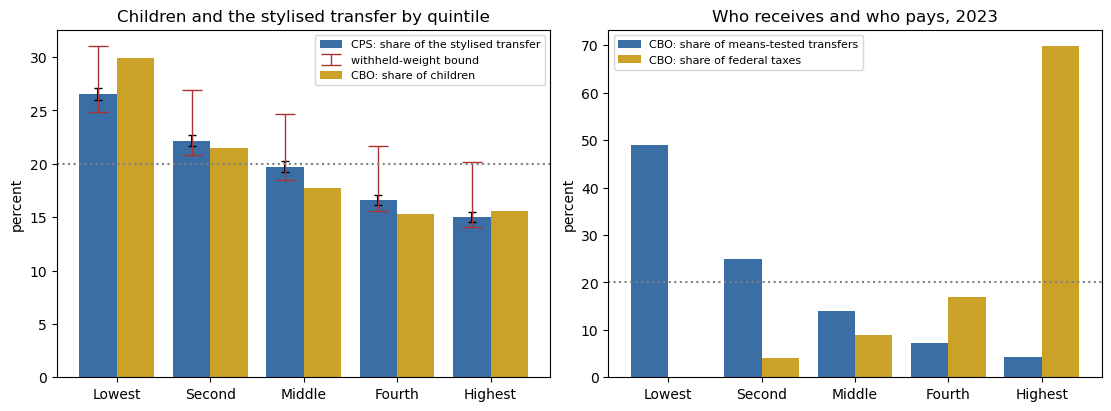

Left: bars are shares of the stylised transfer (CPS, with the sampling interval in black and the withheld-weight bound in red) next to CBO's share of children. Right: CBO's published shares. Dotted line: one fifth.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
x = np.arange(5)
axes[0].bar(x - 0.2, quint["share %"], 0.4, yerr=[quint["share %"] - quint["sampling low"], quint["sampling high"] - quint["share %"]], label="CPS: share of the stylised transfer", color="#3b6ea5", capsize=3)
axes[0].errorbar(x - 0.2, quint["share %"], yerr=[quint["share %"] - quint["withheld low"], quint["withheld high"] - quint["share %"]], fmt="none", ecolor="#a33", capsize=7, lw=1, label="withheld-weight bound")
axes[0].bar(x + 0.2, 100 * cbo_kids / cbo_kids.sum(), 0.4, label="CBO: share of children", color="#c9a227")
axes[0].axhline(20, color="grey", linestyle=":")
axes[0].set_xticks(x, ["Lowest", "Second", "Middle", "Fourth", "Highest"])
axes[0].set_ylabel("percent"); axes[0].set_title("Children and the stylised transfer by quintile"); axes[0].legend(fontsize=8)
tr = cbo["share_transfers"].set_index("Income group").loc[QUINTILES, "Means-tested transfers"].astype(float)
tx = cbo["share_taxes"].set_index("Income group").loc[QUINTILES, "Federal taxes"].astype(float)
axes[1].bar(x - 0.2, tr, 0.4, label="CBO: share of means-tested transfers", color="#3b6ea5")
axes[1].bar(x + 0.2, tx, 0.4, label="CBO: share of federal taxes", color="#c9a227")
axes[1].axhline(20, color="grey", linestyle=":")
axes[1].set_xticks(x, ["Lowest", "Second", "Middle", "Fourth", "Highest"])
axes[1].set_ylabel("percent"); axes[1].set_title("Who receives and who pays, 2023"); axes[1].legend(fontsize=8)
plt.show()
print("Left: bars are shares of the stylised transfer (CPS, with the sampling interval in black and the withheld-weight bound in red) next to CBO's share of children. Right: CBO's published shares. Dotted line: one fifth.")

## Limitations

- **Plan and amendments.** The plan was committed before any retrieval and never edited. Amendment 1 (before the first CPS retrieval) set the bins, tails, floor and a 1% withheld-weight bound. The first CPS retrieval exceeded that bound and stopped; amendment 2 (after that retrieval, on the owner's ruling, before any incidence was computed) moved the bound to 2% and required every share to be bounded by the withheld weight, so the bound was chosen after the figure was seen. The configuration cell prints each file's author time and digest (not its commit id, which a rebase changes):

  | File | Role | Relation to the first CPS retrieval |
  |---|---|---|
  | `E03_plan.md` | the plan | before |
  | `E03_plan_amendment_1.md` | bins, tails, floor, 1% bound | before |
  | `E03_plan_amendment_2.md` | bound moved to 2%, shares bounded by the withheld weight | after |

  The amendments cite their predecessors by commit id as it stood when they were written (the plan as f44a811, amendment 1 as dbf5ce3); rebases have since rewritten commit ids, so those two ids identify `E03_plan.md` and `E03_plan_amendment_1.md`, whose SHA-256 and author times the configuration cell prints, and every binding in this notebook is by file digest and author time, not by commit id.
  The stored provenance is a re-run whose counts match the first retrieval; the first retrieval's record and a run ledger were reconstructed afterwards and are marked as such.
- **The two income concepts differ and are not harmonised.** The table in the data section sets out what each includes. The CPS boundaries sit below CBO's and the CPS puts fewer children in its lowest quintile; the notebook describes that as definition plus measurement without apportioning it. The plan expected to compare mean incomes by quintile; the CBO workbook publishes no size-adjusted mean, so the notebook compares boundaries and counts. That departure was decided on seeing the file on 2026-10-27 and is labelled "not pre-specified (added after review, 2026-10-29)" in its cell.
- **CBO's tax and transfer figures are modelled allocations**, not a count of who writes the cheque: the corporate income tax is split between capital and labour, employers' payroll taxes are charged to workers and Medicaid is valued at cost to the government. The shares of the stylised transfer are estimates of where children are, multiplied by a constant; there is no take-up, phase-out, taxation or behavioural response in the body.
- **Sampling intervals.** The pre-specified intervals use Kish's effective sample size: a simple-random-sample approximation, not a bound. It ignores clustering (siblings share every cell key) and the estimated quintile boundaries, which widen the true interval, and the calibration of the weights to population controls by age, sex, race and Hispanic origin, which narrows it. The Census Bureau's 160 replicate weights give the Bureau's own variance estimate and are the better guide; a labelled analysis ("not pre-specified (added after review, 2026-10-28)") adds those intervals beside the Kish ones and counts the boundaries' uncertainty. In the shares compared the replicate standard error was close to Kish's for the quintile shares, below it for the race shares and above it for the age shares (median ratio 0.98, range 0.37 to 1.44, printed), so the Kish figure errs in both directions and is not a reliable bound either way. The replicate weights are used for variance only. The Bureau's usage instructions describe a file layout (ten-digit weights, 1,617 columns) that does not match the file or its SAS code; the SAS layout was used because it reproduces the file's 161 published column sums and its record count equals the API's. The replicate intervals do not change the pre-specified verdict (the notebook stops and asks if they would). A difference "suggested by the sample" remains conditional on the withheld-weight bound as well.
- **Withheld cells.** The client withholds cells under the record floor and now reports the withheld weight by margin. The bound moved to 2% by amendment 2 assumes nothing about where the withheld people are and holds the quintile boundaries fixed; the labelled analysis that restores the withheld weight by margin moves the boundaries and is a sensitivity analysis. Where the withheld weight sits is read from the margins printed in the notebook. The first draft inferred that it sat in the tails of income and in small groups; the margins show it does not (it sits in the middle income bands and in particular race and reference-person age groups), which is why the bound is not tightened by that inference.
- **Even spread inside a bin.** Quintile boundaries sit inside $2,500 bins and people are taken to be spread evenly across the bin that holds a boundary; the boundary-bin share is printed.
- **Shares from averages.** The plan said to divide each quintile's value by the sum across quintiles. CBO's values are averages per household and the quintiles hold different numbers of households, so that is not a share of the total; the notebook uses CBO's own published shares and checks them against average times households. That departure is stated here and in the cell.
- **Pre-stated direction.** The plan expected the highest quintile's share to be below 20%. Its point share is, but the upper end of the withheld-weight bound reaches 20%, as the notebook prints.
- **Money income is under-reported at both ends** in the CPS, and the public-use file replaces values above the topcode with swapped values, so the top is not what respondents reported; the cap bin holds everyone above its lower edge.
- **Race groups pool small populations.** American Indian and Alaska Native alone, Pacific Islander alone and people of two or more races are combined with a small group of others because the CPS cannot estimate them separately. Hispanic origin takes precedence over race.
- **One income year.** CBO and the CPS are both for income year 2023.
- **Departures from the plan.** The plan was not edited. Beyond the two amendments, the departures are the reconciliation by boundaries and counts and the shares taken from published values, both labelled "not pre-specified (added after review, 2026-10-29)" where they occur, the replicate-weight analysis and the withheld-weight restoration, both labelled "not pre-specified (added after review, 2026-10-28)", and the sampling-interval description, which the plan called a lower bound and this notebook does not.

## Key Takeaways

1. A table of averages is not a table of shares: a quintile's share of a total needs its number of households, and the notebook checks CBO's published shares against that product.
2. Ranking people by income is a choice of income concept. Ranking before transfers and taxes, as CBO does, and ranking by money income, as the CPS does here, put different people in the same quintile; the gap between the two sources is definition plus measurement, not decomposed here, and not an error in either.
3. When income is known only to its bin, a quantile boundary is an interpolation, and the honest report includes how much of the population sits in the bin that holds it.
4. A survey share needs two kinds of caution: a sampling interval, best taken from the survey's own replicate weights (a simple-random-sample approximation can be off in either direction), and a bound set by the weight a disclosure rule withheld. A difference deserves a stronger word only when it survives both.
5. A stylised transfer shows how an instrument's design, here a fixed amount per child, determines who receives it before any behaviour is considered.

## Exercises

1. Replace the fixed amount per child with an amount that falls to zero above a household income threshold you choose. Which quintile's share changes most, and what does the withheld-weight bound say about the change?
2. Rank by `HTOTVAL` less a rough estimate of federal taxes and compare the quintile populations with CBO's again.
3. Compute the share of the transfer going to children in households whose reference person is under 35, and say which of the two intervals matters more for that group.
4. Use CBO's table of income-group minimums for a household of four. How far do the CPS boundaries for four-person households sit from CBO's?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Congressional Budget Office, *The Distribution of Household Income, 2023* (publication 62761) and its supplemental data workbook.
- Kish, L. (1965), *Survey Sampling*, Wiley (effective sample size).
- U.S. Census Bureau (2024), *Estimating ASEC Variances with Replicate Weights* (the usage instructions for the 2024 ASEC replicate-weight file), formula 1; and the file's SAS layout. See `data/cps/SOURCES.md`.
- U.S. Census Bureau, *Current Population Survey Annual Social and Economic Supplement* technical documentation, 2024.